# 14 — El umbral y los ajustes del modelo

**Objetivo:** resolver el problema que arrastramos desde la notebook 09 (en
cardíacos, el random forest **ordena** bien pero, con el umbral 0,5, casi no
reconoce a los normales) con remedios **fijados de antemano**, y probar la
propuesta de la notebook 08 de regularizar más la regresión logística. Al
terminar deberías poder:
- explicar por qué el umbral no cambia el AUC pero sí la sensibilidad y la
  especificidad;
- explicar cómo se elige un umbral **dentro** de la validación, sin mirar los
  datos de prueba, y con qué criterio clínico;
- comparar tres remedios para la especificidad del random forest;
- decir si `C = 0,1` cambia algo en la regresión logística.

Todo se compara contra la línea de base de la notebook 11 (extracción
corregida, sin filtro), con las mismas reglas.

*(La notebook tarda unos 11 minutos en correr entera; la sección 2 es la más
lenta, porque cada modelo se entrena seis veces por partición.)*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.svm import SVC
from xgboost import XGBClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.evaluation import make_pipeline
from src.paths import OUT_DIR

warnings.filterwarnings("ignore")

NO_FEATURES = ["file_id", "label", "label_binary"]
SEMILLA = 0
REPETICIONES = 3
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}
MODELOS = ["Regresión logística", "SVM-RBF", "Random forest", "XGBoost"]

AZUL, NARANJA, AQUA, AMARILLO, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features_corregidas.csv")   # la línea de base (notebook 11)
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values
    return df.drop(columns=NO_FEATURES), df["label_binary"].values, caso, df["label"].values


datos = {s: cargar(s) for s in ["LS", "HS"]}


def modelos(y):
    """Los cuatro modelos de las notebooks 10 y 11, y las tres variantes de esta notebook."""
    peso_xgb = (y == 0).sum() / (y == 1).sum()
    return {
        "Regresión logística": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"),
                                             "class_weight"),
        "SVM-RBF": make_pipeline(SVC(kernel="rbf", class_weight="balanced"), "class_weight"),
        "Random forest": make_pipeline(RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                              random_state=SEMILLA), "class_weight"),
        "XGBoost": make_pipeline(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9,
                                               scale_pos_weight=peso_xgb, eval_metric="logloss",
                                               random_state=SEMILLA, n_jobs=1), "class_weight"),
        # Variantes fijadas de antemano (notebooks 08 y 09)
        "Random forest (hojas de 5)": make_pipeline(RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=SEMILLA), "class_weight"),
        "Random forest (SMOTE)": make_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEMILLA),
                                               "smote"),
        "Regresión logística (C = 0,1)": make_pipeline(LogisticRegression(C=0.1, max_iter=2000,
                                                                          class_weight="balanced"), "class_weight"),
    }


def puntajes(modelo, X, y, cv, grupos=None):
    if hasattr(modelo, "predict_proba"):
        return cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return 1 / (1 + np.exp(-cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="decision_function")))


def ajustar_y_puntuar(modelo, X_entrenamiento, y_entrenamiento, X_prueba):
    m = clone(modelo).fit(X_entrenamiento, y_entrenamiento)
    if hasattr(m, "predict_proba"):
        return m.predict_proba(X_prueba)[:, 1]
    return 1 / (1 + np.exp(-m.decision_function(X_prueba)))


def auc_medio(y, probs):
    return np.mean([roc_auc_score(y, p) for p in probs])


def dif_pareada(y, p_nueva, p_vieja, n=1000):
    """Diferencia de AUC (nueva − vieja) e IC 95 % por bootstrap pareado (notebook 11)."""
    rng = np.random.default_rng(SEMILLA)
    valores = []
    while len(valores) < n:
        m = rng.integers(0, len(y), len(y))
        if len(np.unique(y[m])) == 2:
            valores.append(auc_medio(y[m], [p[m] for p in p_nueva]) - auc_medio(y[m], [p[m] for p in p_vieja]))
    return auc_medio(y, p_nueva) - auc_medio(y, p_vieja), np.percentile(valores, [2.5, 97.5])

## 1. El problema: ordenar bien no alcanza

Recordemos la notebook 09. El AUC mide si el modelo **ordena** bien (si le da
más puntaje a un patológico que a un normal). Para **decidir** hace falta
además un **umbral**: por encima, "patológico". El umbral no cambia el orden,
así que **no cambia el AUC**; pero sí cambia la sensibilidad y la
especificidad.

En cardíacos, el random forest de la línea de base tiene un AUC de 0,82, pero
con el umbral 0,5 su especificidad es 0,00: les da a **todos** los normales
más de 0,5. Su escala está corrida hacia arriba (41 de 50 grabaciones son
patológicas, y las hojas de los árboles completos son puras).

Hay dos maneras de atacarlo:
1. **Mover el umbral**, eligiéndolo bien (sección 2).
2. **Cambiar el modelo** para que su escala no quede corrida: hojas más
   grandes o SMOTE (sección 3).

## 2. Elegir el umbral dentro de la validación

En la notebook 09 vimos que con un umbral más alto el bosque reconoce más
normales. Pero **no se puede elegir mirando la tabla de resultados**: sería
ajustar a los mismos datos con los que evaluamos, y el resultado saldría
optimista. El umbral tiene que elegirse **solo con los datos de
entrenamiento** de cada partición:

1. En cada partición de la validación cruzada, separamos entrenamiento y
   prueba, como siempre.
2. Dentro del entrenamiento hacemos **otra** validación cruzada (interna), que
   nos da probabilidades "honestas" para las grabaciones de entrenamiento.
3. Con esas probabilidades elegimos el umbral.
4. Entrenamos el modelo con todo el entrenamiento, y lo aplicamos a la prueba
   **con ese umbral**.

Las grabaciones de prueba nunca intervienen en la elección. Es la misma lógica
que cuando se elige un punto de corte para una prueba diagnóstica: se fija con
una muestra y se evalúa con otra.

**¿Con qué criterio?** Fijamos dos de antemano, con argumentos clínicos:
- **Youden:** el umbral que maximiza sensibilidad + especificidad (el índice
  de Youden). Le da el mismo peso a los dos errores.
- **Tamizaje:** el umbral más alto que mantiene una sensibilidad de al menos
  0,90 en el entrenamiento. Prioriza no dejar pasar patológicos, como en un
  estudio de tamizaje, y dentro de eso busca la mejor especificidad.

In [2]:
def umbral_youden(y, p):
    fpr, tpr, umbrales = roc_curve(y, p)
    return umbrales[np.argmax(tpr - fpr)]


def umbral_tamizaje(y, p, sensibilidad=0.90):
    fpr, tpr, umbrales = roc_curve(y, p)      # umbrales de mayor a menor; la sensibilidad crece
    return umbrales[np.argmax(tpr >= sensibilidad)]   # el más alto que llega a esa sensibilidad


REGLAS = {"Youden": umbral_youden, "tamizaje": umbral_tamizaje}


def validacion_con_umbral(modelo, X, y):
    """La validación de la notebook 11 (mismas particiones), pero en cada partición se elige además el
    umbral de cada regla con una validación cruzada interna sobre el entrenamiento."""
    resultados = []
    for r in range(REPETICIONES):
        p = np.zeros(len(y))
        umbrales = {regla: np.zeros(len(y)) for regla in REGLAS}
        for entrenamiento, prueba in StratifiedKFold(5, shuffle=True, random_state=r).split(X, y):
            X_tr, y_tr = X.iloc[entrenamiento], y[entrenamiento]
            p_interna = puntajes(modelo, X_tr, y_tr, StratifiedKFold(5, shuffle=True, random_state=100 + r))
            for regla, funcion in REGLAS.items():
                umbrales[regla][prueba] = funcion(y_tr, p_interna)
            p[prueba] = ajustar_y_puntuar(modelo, X_tr, y_tr, X.iloc[prueba])
        resultados.append({"probabilidad": p, **umbrales})
    return resultados


def sens_esp(y, resultados, regla):
    """Sensibilidad, especificidad y exactitud balanceada (promedio de las repeticiones) con una regla."""
    valores = []
    for r in resultados:
        umbral = 0.5 if regla == "0,5" else r[regla]
        pred = r["probabilidad"] >= umbral
        sens, esp = pred[y == 1].mean(), 1 - pred[y == 0].mean()
        valores.append((sens, esp, (sens + esp) / 2))
    return np.mean(valores, axis=0)


inicio = time.time()
validaciones = {}
for subset, (X, y, caso, tipo) in datos.items():
    for nombre, modelo in modelos(y).items():
        validaciones[(subset, nombre)] = validacion_con_umbral(modelo, X, y)
    print(f"{NOMBRE[subset]}: listo")
print(f"({time.time() - inicio:.0f} segundos)")


def tabla_umbrales(subset, nombres):
    y = datos[subset][1]
    filas = {}
    for nombre in nombres:
        res = validaciones[(subset, nombre)]
        fila = {("", "AUC"): auc_medio(y, [r["probabilidad"] for r in res])}
        for regla in ["0,5", "Youden", "tamizaje"]:
            s, e, b = sens_esp(y, res, regla)
            fila.update({(regla, "sens."): s, (regla, "esp."): e, (regla, "exact. bal."): b})
        filas[nombre] = fila
    return pd.DataFrame(filas).T


for subset in datos:
    print(f"\n===== {NOMBRE[subset]} =====")
    print(tabla_umbrales(subset, MODELOS).round(2).to_string())

Pulmonares: listo


Cardíacos: listo
(461 segundos)

===== Pulmonares =====
                            0,5                   Youden                   tamizaje                  
                      AUC sens.  esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Regresión logística  1.00  1.00  0.86        0.93   0.92  1.00        0.96     0.96  1.00        0.98
SVM-RBF              0.98  0.98  0.83        0.91   0.89  0.92        0.91     0.90  0.92        0.91
Random forest        0.93  1.00  0.56        0.78   0.86  0.78        0.82     0.91  0.75        0.83
XGBoost              0.87  0.91  0.75        0.83   0.85  0.78        0.81     0.93  0.72        0.83

===== Cardíacos =====
                            0,5                   Youden                   tamizaje                  
                      AUC sens.  esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Regresión logística  0.83  0.86  0.70        0.78   0.79  0.70        0.75     0.89  0.56        0.72
SVM

**Cómo leerla:**
- El **AUC no cambia** con el umbral: es el mismo de la notebook 11, porque
  mover el umbral no cambia el orden.
- En **cardíacos**, el random forest pasa de no reconocer ningún normal
  (especificidad 0,00 con 0,5) a reconocer 0,63 con Youden, a cambio de
  detectar menos patológicos (sensibilidad de 0,98 a 0,74). Con el criterio de
  tamizaje mantiene la sensibilidad en 0,93 y reconoce 0,41 de los normales.
- El **SVM-RBF** con Youden queda con el punto más equilibrado de cardíacos:
  sensibilidad 0,79 y especificidad 0,89 (exactitud balanceada 0,84).
- La **regresión logística** ya estaba equilibrada con 0,5 (0,86 y 0,70):
  mover el umbral no la mejora.
- En **pulmonares**, la regresión logística con el criterio de tamizaje
  queda en sensibilidad 0,96 y especificidad 1,00.

**Cuidado con los decimales:** en cardíacos hay 9 normales, así que cada
normal vale 0,11 de especificidad. Una diferencia de 0,1 o 0,2 es uno o dos
normales.

El mismo resultado en un gráfico: cada modelo con el umbral 0,5 (círculo
vacío), con Youden (círculo lleno) y con el criterio de tamizaje (cuadrado).

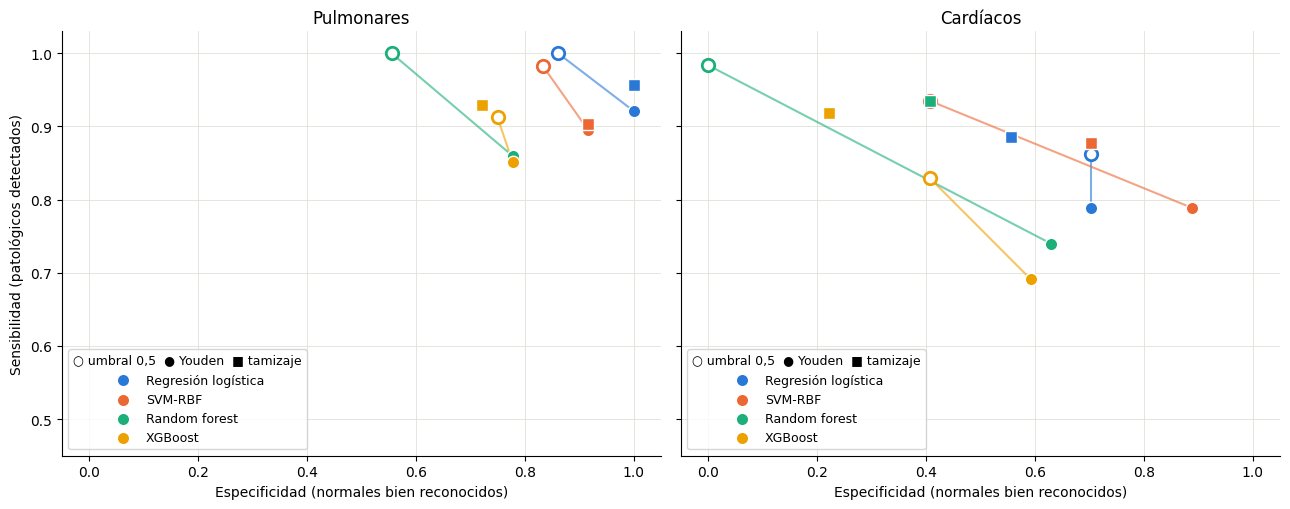

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, subset in zip(axes, datos):
    y = datos[subset][1]
    for nombre, color in zip(MODELOS, [AZUL, NARANJA, AQUA, AMARILLO]):
        res = validaciones[(subset, nombre)]
        puntos = {regla: sens_esp(y, res, regla) for regla in ["0,5", "Youden", "tamizaje"]}
        ax.plot([puntos[r][1] for r in ["0,5", "Youden"]], [puntos[r][0] for r in ["0,5", "Youden"]],
                color=color, lw=1.5, alpha=0.6)
        ax.scatter(puntos["0,5"][1], puntos["0,5"][0], s=80, facecolor="white", edgecolor=color, lw=2, zorder=3)
        ax.scatter(puntos["Youden"][1], puntos["Youden"][0], s=80, color=color, edgecolor="white", lw=1, zorder=3,
                   label=nombre)
        ax.scatter(puntos["tamizaje"][1], puntos["tamizaje"][0], s=70, marker="s", color=color, edgecolor="white",
                   lw=1, zorder=3)
    ax.set(xlim=(-0.05, 1.05), ylim=(0.45, 1.03), title=NOMBRE[subset],
           xlabel="Especificidad (normales bien reconocidos)")
    ax.legend(loc="lower left", fontsize=9, title="○ umbral 0,5  ● Youden  ■ tamizaje", title_fontsize=9)
axes[0].set_ylabel("Sensibilidad (patológicos detectados)")
fig.tight_layout()

Cada línea une el umbral 0,5 (círculo vacío) con Youden (círculo lleno). En
cardíacos, mover el umbral lleva a los modelos desde la izquierda (casi sin
especificidad) hacia el centro: se cambia sensibilidad por especificidad,
moviéndose sobre la curva ROC de cada modelo. Ningún punto llega al rincón
ideal (arriba a la derecha): con un AUC de ~0,8, no existe un umbral que sea
bueno en las dos cosas a la vez.

## 3. Tres remedios para el random forest

Los tres quedaron fijados en las notebooks 09 y 10, antes de esta:
1. **Hojas de al menos 5 grabaciones** (`min_samples_leaf=5`). Las hojas ya no
   son puras, y el peso de las clases (`class_weight`) vuelve a actuar sobre el
   voto (notebook 09, sección 7).
2. **SMOTE** en vez de `class_weight`: entrenar con clases equilibradas, con
   normales sintéticos, genera más hojas "normales" (notebook 10).
3. **El umbral elegido dentro de la validación** (sección 2).

Los dos primeros cambian el modelo, así que también pueden cambiar el AUC. Lo
comparamos con el bosque de la línea de base con el bootstrap pareado.

In [4]:
BOSQUES = ["Random forest", "Random forest (hojas de 5)", "Random forest (SMOTE)"]
for subset in datos:
    y = datos[subset][1]
    base = [r["probabilidad"] for r in validaciones[(subset, "Random forest")]]
    print(f"\n===== {NOMBRE[subset]} =====")
    print(tabla_umbrales(subset, BOSQUES).round(2).to_string())
    for nombre in BOSQUES[1:]:
        d, (bajo, alto) = dif_pareada(y, [r["probabilidad"] for r in validaciones[(subset, nombre)]], base)
        print(f"  {nombre}: diferencia de AUC con el bosque base {d:+.3f} (IC 95 % {bajo:+.3f} a {alto:+.3f})")


===== Pulmonares =====
                                   0,5                   Youden                   tamizaje                  
                             AUC sens.  esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Random forest               0.93  1.00  0.56        0.78   0.86  0.78        0.82     0.91  0.75        0.83
Random forest (hojas de 5)  0.92  0.98  0.67        0.82   0.86  0.78        0.82     0.89  0.69        0.79
Random forest (SMOTE)       0.94  0.96  0.75        0.86   0.82  0.81        0.82     0.86  0.75        0.80


  Random forest (hojas de 5): diferencia de AUC con el bosque base -0.004 (IC 95 % -0.028 a +0.016)


  Random forest (SMOTE): diferencia de AUC con el bosque base +0.016 (IC 95 % -0.010 a +0.049)

===== Cardíacos =====
                                   0,5                   Youden                   tamizaje                  
                             AUC sens.  esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Random forest               0.82  0.98  0.00        0.49   0.74  0.63        0.68     0.93  0.41        0.67
Random forest (hojas de 5)  0.79  0.93  0.37        0.65   0.74  0.67        0.70     0.89  0.44        0.67
Random forest (SMOTE)       0.81  0.91  0.33        0.62   0.74  0.63        0.68     0.93  0.48        0.70


  Random forest (hojas de 5): diferencia de AUC con el bosque base -0.037 (IC 95 % -0.073 a -0.002)


  Random forest (SMOTE): diferencia de AUC con el bosque base -0.012 (IC 95 % -0.082 a +0.037)


**Cómo leerlo (cardíacos):**
- **Hojas de 5:** la especificidad con 0,5 sube de 0,00 a 0,37, pero el AUC
  baja un poco (de 0,82 a 0,79): según el bootstrap pareado, una baja chica
  pero real.
- **SMOTE:** parecido: especificidad 0,33 con 0,5 y AUC 0,81 (esta diferencia
  de AUC no se distingue del azar).
- **El umbral elegido dentro de la validación** (Youden) es el que más ayuda,
  sin tocar el modelo ni el AUC: especificidad 0,63.

Los tres remedios van en la misma dirección, pero el umbral es el más simple
y el único que no cambia el orden. En pulmonares el patrón es parecido: el
bosque pasa de 0,56 a 0,78 de especificidad con Youden.

## 4. La regresión logística con `C = 0,1`

En la notebook 08 propusimos regularizar más (`C = 0,1` en vez de 1) con un
argumento teórico: con muchas más features que grabaciones (p ≫ n), la
varianza domina, y achicar más los pesos debería estabilizar el modelo. Lo
probamos, con el umbral y con el control de pseudo-casos, porque una
regularización más fuerte también podría reducir la fuga por caso.

In [5]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


REGRESIONES = ["Regresión logística", "Regresión logística (C = 0,1)"]
filas = []
for subset, (X, y, caso, tipo) in datos.items():
    print(f"\n===== {NOMBRE[subset]} =====")
    print(tabla_umbrales(subset, REGRESIONES).round(2).to_string())
    d, (bajo, alto) = dif_pareada(y, [r["probabilidad"] for r in validaciones[(subset, REGRESIONES[1])]],
                                  [r["probabilidad"] for r in validaciones[(subset, REGRESIONES[0])]])
    print(f"  diferencia de AUC (C = 0,1 menos C = 1): {d:+.3f} (IC 95 % {bajo:+.3f} a {alto:+.3f})")
    rng = np.random.default_rng(SEMILLA)
    sorteos = [pseudo_casos(caso, y, rng) for _ in range(5)]
    for nombre in REGRESIONES:
        modelo = modelos(y)[nombre]
        pseudo = [roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), g)) for g in sorteos]
        real = roc_auc_score(y, puntajes(modelo, X, y, LeaveOneGroupOut(), caso))
        filas.append({"subconjunto": NOMBRE[subset], "modelo": nombre, "pseudo-caso (media)": np.mean(pseudo),
                      "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}", "caso real": real,
                      "¿fuga?": "sí" if real < np.min(pseudo) else "no medible"})
print("\nControl de pseudo-casos:")
print(pd.DataFrame(filas).round(3).to_string(index=False))


===== Pulmonares =====
                                     0,5                   Youden                   tamizaje                  
                               AUC sens.  esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Regresión logística            1.0  1.00  0.86        0.93   0.92  1.00        0.96     0.96  1.00        0.98
Regresión logística (C = 0,1)  1.0  0.99  0.89        0.94   0.92  0.97        0.95     0.96  0.97        0.96


  diferencia de AUC (C = 0,1 menos C = 1): -0.002 (IC 95 % -0.009 a +0.000)



===== Cardíacos =====
                                      0,5                  Youden                   tamizaje                  
                                AUC sens. esp. exact. bal.  sens.  esp. exact. bal.    sens.  esp. exact. bal.
Regresión logística            0.83  0.86  0.7        0.78   0.79  0.70        0.75     0.89  0.56        0.72
Regresión logística (C = 0,1)  0.83  0.85  0.7        0.78   0.78  0.89        0.83     0.87  0.56        0.71


  diferencia de AUC (C = 0,1 menos C = 1): +0.005 (IC 95 % -0.019 a +0.032)



Control de pseudo-casos:
subconjunto                        modelo  pseudo-caso (media) pseudo-caso (mín–máx)  caso real     ¿fuga?
 Pulmonares           Regresión logística                0.989             0.98–1.00      0.956         sí
 Pulmonares Regresión logística (C = 0,1)                0.984             0.98–1.00      0.954         sí
  Cardíacos           Regresión logística                0.715             0.58–0.82      0.732 no medible
  Cardíacos Regresión logística (C = 0,1)                0.714             0.58–0.81      0.748 no medible


**Cómo leerlo:** `C = 0,1` no cambia el AUC (la diferencia es mínima en los
dos subconjuntos) ni el control de pseudo-casos. Lo que sí cambia es la
escala de las probabilidades: con pesos más chicos, quedan menos extremas, y
el umbral elegido en el entrenamiento se traslada algo mejor a la prueba (en
cardíacos, con Youden, la especificidad pasa de 0,70 a 0,89 con una
sensibilidad parecida). Pero con 9 normales eso son una o dos grabaciones: no
alcanza para preferir un `C` sobre el otro. La propuesta de la notebook 08 no
cambia las conclusiones.

## 5. Qué nos llevamos

1. **El umbral importa tanto como el modelo.** El AUC no alcanza para decidir:
   con el umbral 0,5, el random forest cardíaco no sirve para descartar
   (especificidad 0), y con un umbral elegido dentro de la validación reconoce
   6 de cada 10 normales, con el mismo AUC.
2. **Cómo elegir el umbral:** siempre dentro de la validación, con un criterio
   clínico fijado de antemano. Para tamizaje, sensibilidad de al menos 0,90;
   para equilibrar los dos errores, Youden.
3. **De los tres remedios del bosque, el umbral es el mejor:** las hojas de 5 y
   SMOTE mejoran la especificidad con 0,5, pero bajan un poco el AUC.
4. **`C = 0,1`** no cambia el AUC ni la fuga; su efecto sobre la escala es
   chico.
5. **Para la tesis:** reportar cada modelo con su AUC y, además, con la
   sensibilidad y la especificidad en un umbral elegido dentro de la
   validación, aclarando el criterio. En cardíacos, los puntos más
   equilibrados son el del SVM-RBF con Youden (0,79 y 0,89) y el de la
   regresión logística con 0,5 (0,86 y 0,70); con 9 normales, la diferencia
   entre ellos es de una o dos grabaciones.

## 6. Cómo explicárselo a tu directora (en 5 frases)

1. *"El AUC mide si el modelo ordena bien; para decidir hace falta un umbral, y
   con 0,5 el random forest cardíaco no reconocía ningún normal."*
2. *"Elegí el umbral dentro de la validación cruzada, solo con los datos de
   entrenamiento de cada partición, con dos criterios fijados de antemano:
   Youden (equilibrio) y tamizaje (sensibilidad de al menos 0,90)."*
3. *"Con Youden, el bosque pasa de 0 a 0,63 de especificidad sin cambiar el
   AUC; las alternativas (hojas más grandes o SMOTE) ayudan menos y bajan un
   poco el AUC."*
4. *"En cardíacos, el punto más equilibrado es el del SVM-RBF con Youden
   (sensibilidad 0,79, especificidad 0,89), aunque con 9 normales las
   diferencias entre modelos son de una o dos grabaciones."*
5. *"Regularizar más la regresión logística (C = 0,1) no cambia el AUC ni la
   fuga por caso."*

## 7. Tu turno

El criterio de tamizaje pide una sensibilidad de al menos 0,90. ¿Qué pasa si
lo hacés más exigente o más laxo? La celda prueba 0,80, 0,90 y 0,95 en
cardíacos (cambiá la lista si querés otros valores). *(Tarda alrededor de un
minuto.)*

In [6]:
SENSIBILIDADES = [0.80, 0.90, 0.95]

X, y, caso, tipo = datos["HS"]
filas = {}
for nombre in ["Regresión logística", "Random forest"]:
    modelo = modelos(y)[nombre]
    pred = {s: [] for s in SENSIBILIDADES}
    for r in range(REPETICIONES):
        p = np.zeros(len(y))
        umbrales = {s: np.zeros(len(y)) for s in SENSIBILIDADES}
        for entrenamiento, prueba in StratifiedKFold(5, shuffle=True, random_state=r).split(X, y):
            X_tr, y_tr = X.iloc[entrenamiento], y[entrenamiento]
            p_interna = puntajes(modelo, X_tr, y_tr, StratifiedKFold(5, shuffle=True, random_state=100 + r))
            for s in SENSIBILIDADES:
                umbrales[s][prueba] = umbral_tamizaje(y_tr, p_interna, s)
            p[prueba] = ajustar_y_puntuar(modelo, X_tr, y_tr, X.iloc[prueba])
        for s in SENSIBILIDADES:
            pred[s].append(p >= umbrales[s])
    for s in SENSIBILIDADES:
        filas[(nombre, f"sensibilidad pedida ≥ {s:.2f}")] = {
            "sens.": np.mean([d[y == 1].mean() for d in pred[s]]),
            "esp.": np.mean([1 - d[y == 0].mean() for d in pred[s]])}
print(pd.DataFrame(filas).T.round(2).to_string())

                                                sens.  esp.
Regresión logística sensibilidad pedida ≥ 0.80   0.84  0.74
                    sensibilidad pedida ≥ 0.90   0.89  0.56
                    sensibilidad pedida ≥ 0.95   0.93  0.41
Random forest       sensibilidad pedida ≥ 0.80   0.84  0.56
                    sensibilidad pedida ≥ 0.90   0.93  0.41
                    sensibilidad pedida ≥ 0.95   0.94  0.33


**Lo que da:** cuanta más sensibilidad pedís, menos especificidad. Con la
regresión logística, pidiendo de 0,80 a 0,95, la sensibilidad lograda sube
de 0,84 a 0,93 y la especificidad baja de 0,74 a 0,41. Es moverse sobre la
curva ROC: no hay umbral "gratis".

Fijate también que la sensibilidad lograda queda cerca de la pedida, pero no
exacta (0,84 pidiendo 0,80; 0,93 pidiendo 0,95): el umbral se elige con las
grabaciones de entrenamiento y se aplica a grabaciones que el modelo no vio.
Qué sensibilidad pedir es una **decisión clínica**, que se fija antes de mirar
los resultados: depende de para qué se usaría el clasificador.

## Preguntas de control

1. ¿Por qué el umbral no cambia el AUC? ¿Qué cambia?
2. ¿Por qué no se puede elegir el umbral mirando la tabla de resultados? ¿Cómo
   se elige bien?
3. ¿Qué diferencia hay entre el criterio de Youden y el de tamizaje? ¿Cuál
   usarías para un estudio de tamizaje, y por qué?
4. ¿Qué hacen `min_samples_leaf=5` y SMOTE para que el random forest reconozca
   más normales? ¿Cuál anduvo mejor?
5. ¿Cambió algo `C = 0,1` en la regresión logística?
6. Con todo lo visto, ¿qué modelo y qué umbral propondrías para cada
   subconjunto?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** Porque el AUC depende solo del orden de los puntajes, y cambiar el
umbral no cambia el orden. Lo que cambia es cuántas grabaciones quedan de
cada lado: la sensibilidad y la especificidad.

**2.** Porque sería ajustar el umbral a los mismos datos con los que se
evalúa, y el resultado saldría optimista. Se elige dentro de la validación:
en cada partición, con una validación cruzada interna sobre el
entrenamiento, y se aplica a la prueba sin tocarlo.

**3.** Youden maximiza sensibilidad + especificidad: los dos errores pesan
igual. El de tamizaje busca la mejor especificidad con una sensibilidad de al
menos 0,90: prioriza no dejar pasar patológicos. Para tamizaje, el segundo,
porque un falso negativo (un patológico que no se detecta) cuesta más que un
falso positivo (un estudio de más).

**4.** Con hojas de 5, cada hoja mezcla clases y el peso de las clases vuelve
a influir en el voto; con SMOTE, el bosque se entrena con clases
equilibradas y aparecen hojas "normales". Las dos suben la especificidad con
0,5, pero bajan un poco el AUC (las hojas de 5, de forma chica pero real).
Anduvo mejor el umbral elegido dentro de la validación: más especificidad,
sin tocar el modelo ni el AUC.

**5.** No: el AUC y el control de pseudo-casos quedan iguales. Cambia un poco
la escala de las probabilidades, pero el efecto sobre la especificidad es de
una o dos grabaciones.

**6.** Una propuesta razonable: en pulmonares, la regresión logística (con la
banda clínica y la normalización de la notebook 12) y el umbral de tamizaje,
que en la línea de base da sensibilidad 0,96 y especificidad 1,00. En
cardíacos, la regresión logística o el SVM-RBF con un umbral elegido dentro
de la validación, aclarando que ningún modelo se separa de los demás y que
las arritmias siguen siendo la limitación.